# WiPER Benchmarking — v12: valutazione open-set rigorosa

Finora il protocollo era *identity-disjoint* (le identità di test non compaiono mai nel training) ma **closed-set** sulla gallery: ogni probe aveva sempre la propria identità iscritta. Qui si aggiunge il caso reale: **alcune persone di test non sono iscritte e il sistema deve rifiutarle**.

## Protocollo

Per ogni fold (33 identità di training, 11 di test, come v7–v11) e per `n_repeats` partizioni casuali delle 11 identità di test:

* **Note** (`n_known`, default 7): iscritte nella gallery.
* **Sconosciute** (le restanti 4): non iscritte; compaiono solo come probe e il sistema deve **rifiutarle**.
* Modello (standardizzazione, LDA) stimato **solo sulle 33 identità di training**: nessuna informazione sulle identità di test.

| Protocollo | Gallery (solo identità note) | Probe (note + sconosciute) |
|---|---|---|
| `cross` | registrazioni `saluto` | `tpose` |
| `cross_rev` | `tpose` | `saluto` |
| `same_saluto` / `same_tpose` | registrazioni della stessa azione | tutte le registrazioni della stessa azione; per un probe noto la propria registrazione è esclusa dalla gallery |

Per ogni probe: similarità coseno con ogni registrazione della gallery → punteggio per identità = massimo → identità candidata = quella col punteggio più alto. Punteggio di accettazione `s`: **`max`** (la similarità migliore) oppure **`margin`** (migliore − seconda migliore identità). Un probe è **accettato** se `s > τ`.

## Metriche

* **DIR@FAR** (Detection and Identification Rate): quota di probe *noti* identificati **correttamente e accettati**, alla soglia per cui una frazione `FAR` di probe *sconosciuti* viene (erroneamente) accettata. È la metrica open-set di riferimento.
* **Rank-1 (noti)**: identificazione closed-set sui soli probe noti, senza soglia (chance ≈ 1/n_known).
* **AUROC di detection**: separazione fra punteggi dei probe noti e sconosciuti (ignora se l'identità è giusta).
* **Verifica (EER, AUROC)**: su tutte le coppie probe–gallery, stessa persona contro persone diverse.
* **Scomposizione a FAR 5%**: corretti accettati / accettati ma sbagliati / rifiutati.
* **Soglia calibrata solo sul training**: una soglia *non* può essere scelta guardando le identità di test. Per ogni fold la si calibra con una CV interna sulle **sole 33 identità di training** (modello addestrato su 22, open-set su 11 identità tenute fuori) e la si applica al test: si riportano FAR e DIR **realizzati** contro il FAR obiettivo.

> Limiti: 4 identità sconosciute per fold e 4 fold ⇒ stime con intervalli ampi (si riporta la deviazione standard fra fold). Con pochi probe sconosciuti, un FAR dell'1% non è risolvibile finemente. Le identità sconosciute provengono dalla stessa campagna di acquisizione delle note: è open-set sulle persone, non su altri ambienti.

## 1. Imports e configurazione

In [1]:
import os, re, random, time
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import rankdata
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

pd.set_option('display.max_columns', None); pd.set_option('display.width', 250)

CFG = dict(
    seed=42,
    output_folder='./output/',
    sanitization='zscore',            # ampiezze: 'raw' | 'hampel' | 'zscore' | 'iqr'
    exclude_ids=('vuoto',),
    gallery_action='saluto', probe_action='tpose',
    n_subcarriers=52,
    phase_outlier_z=3.0,
    n_folds=4,
    # --- open-set ---
    known_fraction=0.64,              # 0.64 * 11 identità di test -> 7 note / 4 sconosciute
    n_repeats=10,                     # partizioni note/sconosciute per fold
    far_levels=(0.01, 0.05, 0.10, 0.20),
    calib_far=(0.01, 0.05, 0.10),     # FAR obiettivo per la soglia calibrata sul training
    inner_folds=3,                    # CV interna per la calibrazione
    score_types=('max', 'margin'),
    lda_dim=20,                       # dimensione FISSA dell'embedding LDA (stessa per modelli interni ed esterni, vedi §3)
)

SANITIZATION_DIRS = {
    'raw':    ('CSV', 'raw_amplitudes'),
    'hampel': ('CSV', 'sanitized_amplitudes', 'HF_amplitudes'),
    'zscore': ('CSV', 'sanitized_amplitudes', 'zscore_amplitudes'),
    'iqr':    ('CSV', 'sanitized_amplitudes', 'iqr_amplitudes'),
}
amp_dir = os.path.join(CFG['output_folder'], *SANITIZATION_DIRS[CFG['sanitization']])
csi_dir = os.path.join(CFG['output_folder'], 'CSV', 'csi_matrices')
random.seed(CFG['seed']); np.random.seed(CFG['seed'])

## 2. Caricamento, fase, feature e fold sulle identità

In [2]:
KEY_RE = re.compile(r'^(?P<sid>[^_]+)_(?P<act>[A-Za-z]+)(?P<num>\d+)$')
assert os.path.isdir(amp_dir), f'Cartella non trovata: {amp_dir}'
assert os.path.isdir(csi_dir), f'Cartella non trovata: {csi_dir}'

def load_amp(key):
    return pd.read_csv(os.path.join(amp_dir, key + '.csv')).drop(columns='timestamp', errors='ignore').to_numpy(dtype=np.float64)

def load_csi(key):
    df = pd.read_csv(os.path.join(csi_dir, key + '.csv')).drop(columns='timestamp', errors='ignore')
    return df.to_numpy().astype(str).astype(complex)

def phase_residual(H):
    ph = np.unwrap(np.angle(H), axis=1)
    k = np.arange(H.shape[1]).astype(float); kc = k - k.mean()
    slope = (ph * kc).sum(axis=1) / (kc ** 2).sum()
    icpt = ph.mean(axis=1) - slope * k.mean()
    return ph - (slope[:, None] * k[None, :] + icpt[:, None])

def zscore_fill(M, thr):
    if thr is None: return M
    mu, sd = M.mean(0), M.std(0) + 1e-12
    return pd.DataFrame(M).mask(np.abs((M - mu) / sd) > thr).ffill().bfill().to_numpy()

recs = []
for fname in sorted(os.listdir(amp_dir)):
    if not fname.endswith('.csv'): continue
    key = fname[:-4]
    if key.split('_')[0] in CFG['exclude_ids']: continue
    m = KEY_RE.match(key)
    if not m: print('ignorato:', key); continue
    A, H = load_amp(key), load_csi(key)
    assert A.shape == H.shape == (A.shape[0], CFG['n_subcarriers']), f'{key}: forme incoerenti {A.shape} vs {H.shape}'
    recs.append(dict(sid=m.group('sid'), act=m.group('act').lower(), num=int(m.group('num')), rec_id=key,
                     A=A, P=zscore_fill(phase_residual(H), CFG['phase_outlier_z'])))

R = len(recs)
rec_sid = np.array([r['sid'] for r in recs]); rec_act = np.array([r['act'] for r in recs])
GAL, PRB = CFG['gallery_action'], CFG['probe_action']
assert GAL in set(rec_act) and PRB in set(rec_act)
print(f'{R} registrazioni | {len(set(rec_sid))} identità | azioni {sorted(set(map(str, rec_act)))}')

def feature_groups(A, P):
    X = A / (A.mean() + 1e-8)
    return {'static': X.mean(0), 'dyn_std': X.std(0), 'diff': np.abs(np.diff(X, axis=0)).mean(0),
            'ph_static': P.mean(0), 'ph_std': P.std(0), 'ph_diff': np.abs(np.diff(P, axis=0)).mean(0)}

fw = defaultdict(list)
for r in recs:
    for k, v in feature_groups(r['A'], r['P']).items(): fw[k].append(v)
feat = {k: np.stack(v) for k, v in fw.items()}
FEATURE_SETS = {'amp static': ['static'], 'ph all': ['ph_static', 'ph_std', 'ph_diff'],
                'amp basic + ph all': ['static', 'dyn_std', 'diff', 'ph_static', 'ph_std', 'ph_diff']}
XS = {n: np.concatenate([feat[g] for g in gs], axis=1) for n, gs in FEATURE_SETS.items()}

def natural_key(s): return [int(t) if t.isdigit() else t for t in re.split(r'(\d+)', s)]
all_ids = sorted(set(rec_sid), key=natural_key)
rng = np.random.RandomState(CFG['seed']); perm = rng.permutation(len(all_ids))
fold_ids = [sorted([all_ids[i] for i in chunk], key=natural_key) for chunk in np.array_split(perm, CFG['n_folds'])]
folds = [(np.where(~np.isin(rec_sid, t))[0], np.where(np.isin(rec_sid, t))[0]) for t in fold_ids]
print('Fold (identità test / train):', [(len(t), len(set(rec_sid[tr]))) for t, (tr, _) in zip(fold_ids, folds)])
n_test_ids = len(fold_ids[0]); n_known = int(round(CFG['known_fraction'] * n_test_ids))
print(f'Open-set per fold: {n_known} identità note (gallery) + {n_test_ids - n_known} sconosciute (solo probe); {CFG["n_repeats"]} partizioni')

440 registrazioni | 44 identità | azioni ['saluto', 'tpose']
Fold (identità test / train): [(11, 33), (11, 33), (11, 33), (11, 33)]
Open-set per fold: 7 identità note (gallery) + 4 sconosciute (solo probe); 10 partizioni


## 3. Modelli (feature + LDA, stimati solo sul training) e baseline casuale

**Dimensione dell'embedding fissata (`lda_dim=20`).** La similarità coseno fra vettori indipendenti ha dispersione ~1/√d: se il modello interno (22 identità ⇒ al più 21 dimensioni LDA) e quello esterno (33 identità ⇒ 32 dimensioni) avessero dimensioni diverse, le loro distribuzioni dei punteggi non sarebbero confrontabili e una soglia calibrata sull'interno risulterebbe sistematicamente troppo alta per l'esterno (FAR reale ≈ 0). Con la stessa dimensione la soglia si trasferisce.

In [3]:
def l2(Z): return Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-12)

def standardize(X, tr, mode):
    X = np.asarray(X, float); act = rec_act
    if mode == 'pooled':
        mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-8
        return (X - mu) / sd
    Z = np.empty_like(X)                                               # 'zscore': statistiche separate per azione, stimate sul training
    for a in np.unique(act):
        tra = tr[act[tr] == a]; m = act == a
        Z[m] = (X[m] - X[tra].mean(0)) / (X[tra].std(0) + 1e-8)
    return Z

def embed_model(X, tr, mode):
    Z = standardize(X, tr, mode)
    n_comp = int(min(CFG['lda_dim'], len(set(rec_sid[tr])) - 1))        # stessa dimensione per training interno (22 id) ed esterno (33 id)
    lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto', n_components=n_comp).fit(Z[tr], rec_sid[tr])
    return l2(lda.transform(Z))

MODELS = [('amp static', 'pooled'), ('ph all', 'pooled'), ('ph all', 'zscore'),
          ('amp basic + ph all', 'pooled'), ('amp basic + ph all', 'zscore')]
def mname(m): return f'{m[0]} | {"z per azione" if m[1] == "zscore" else "pooled"} (LDA)'
MODEL_NAMES = [mname(m) for m in MODELS] + ['RANDOM (baseline)']

def get_embeddings(model_idx, tr, seed):
    # embedding di tutte le registrazioni per un modello addestrato sulle sole registrazioni 'tr'
    if model_idx == len(MODELS):                                       # baseline casuale
        return l2(np.random.RandomState(seed).randn(R, CFG['lda_dim']))
    fs, mode = MODELS[model_idx]
    return embed_model(XS[fs], tr, mode)

## 4. Punteggi open-set e metriche

In [4]:
PROTO_DEF = {'cross': (GAL, PRB, False), 'cross_rev': (PRB, GAL, False),
             f'same_{GAL}': (GAL, GAL, True), f'same_{PRB}': (PRB, PRB, True)}
PROTOCOLS = list(PROTO_DEF)

def open_set_arrays(E, test_idx, known_ids, protocol):
    # punteggi di tutti i probe di test contro la gallery delle sole identità note
    g_act, p_act, loo = PROTO_DEF[protocol]
    p_idx = test_idx[rec_act[test_idx] == p_act]
    g_idx = test_idx[(rec_act[test_idx] == g_act) & np.isin(rec_sid[test_idx], known_ids)]
    sim = E[p_idx] @ E[g_idx].T
    if loo:                                                            # stessa azione: il probe noto non può trovare se stesso
        where = {gi: j for j, gi in enumerate(g_idx)}
        for i, pi in enumerate(p_idx):
            if pi in where: sim[i, where[pi]] = -np.inf
    ids = list(known_ids)
    id_scores = np.stack([sim[:, rec_sid[g_idx] == u].max(axis=1) for u in ids], axis=1)      # [n_probe, n_known]
    best = id_scores.max(axis=1); second = np.partition(id_scores, -2, axis=1)[:, -2]
    top_id = np.array(ids)[id_scores.argmax(axis=1)]
    is_known = np.isin(rec_sid[p_idx], known_ids)
    same = rec_sid[p_idx][:, None] == rec_sid[g_idx][None, :]; ok = np.isfinite(sim)
    return {'max': best, 'margin': best - second, 'correct': (top_id == rec_sid[p_idx]) & is_known, 'known': is_known,
            'pos': sim[same & ok], 'neg': sim[~same & ok]}

def pool(list_of_dicts):
    return {k: np.concatenate([d[k] for d in list_of_dicts]) for k in list_of_dicts[0]}

def auc_from_scores(pos, neg):
    if len(pos) == 0 or len(neg) == 0: return np.nan
    r = rankdata(np.concatenate([pos, neg]))
    return float((r[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg)))

def eer(pos, neg):
    if len(pos) == 0 or len(neg) == 0: return np.nan
    thr = np.unique(np.concatenate([pos, neg])); ps, ns = np.sort(pos), np.sort(neg)
    frr = np.searchsorted(ps, thr, side='left') / len(ps)
    far = 1.0 - np.searchsorted(ns, thr, side='left') / len(ns)
    i = np.argmin(np.abs(far - frr)); return float(0.5 * (far[i] + frr[i]))

def threshold_for_far(unk_scores, far):
    # soglia tale che la frazione di sconosciuti accettati (s > tau) sia <= far
    n = len(unk_scores); k = int(np.floor(far * n))
    return np.sort(unk_scores)[::-1][k] if k < n else -np.inf

def decision_rates(arr, score_type, tau):
    s, kn, cor = arr[score_type], arr['known'], arr['correct']
    acc = s > tau
    return {'FAR': float(acc[~kn].mean()) if (~kn).any() else np.nan,
            'DIR': float((acc & cor)[kn].mean()) if kn.any() else np.nan,
            'wrong_accept': float((acc & ~cor)[kn].mean()) if kn.any() else np.nan,
            'reject': float((~acc)[kn].mean()) if kn.any() else np.nan}

def dir_at_far(arr, score_type, far):
    tau = threshold_for_far(arr[score_type][~arr['known']], far)
    return decision_rates(arr, score_type, tau), tau

def summarize(arr):
    out = {'rank1_known': float(arr['correct'][arr['known']].mean()), 'n_unknown': int((~arr['known']).sum()),
           'ver_auc': auc_from_scores(arr['pos'], arr['neg']), 'ver_eer': eer(arr['pos'], arr['neg'])}
    for st in CFG['score_types']:
        out[f'det_auc_{st}'] = auc_from_scores(arr[st][arr['known']], arr[st][~arr['known']])
        for f in CFG['far_levels']:
            out[f'dir_{st}_{f}'] = dir_at_far(arr, st, f)[0]['DIR']
        d5 = dir_at_far(arr, st, 0.05)[0]
        out[f'wrong_{st}'] = d5['wrong_accept']; out[f'reject_{st}'] = d5['reject']
    return out

def known_splits(fold, ids_pool, n_known_, n_rep, salt):
    r = np.random.RandomState(CFG['seed'] + 1000 * salt + fold)
    return [list(r.choice(ids_pool, n_known_, replace=False)) for _ in range(n_rep)]

# --- sanity: con embedding casuali DIR@FAR ≈ FAR x P(identificazione corretta) ---
_E = l2(np.random.RandomState(0).randn(R, CFG['lda_dim'])); _arrs = []
for f, (tr, te) in enumerate(folds):
    for kn in known_splits(f, fold_ids[f], n_known, CFG['n_repeats'], 0): _arrs.append(open_set_arrays(_E, te, kn, 'cross'))
_a = pool(_arrs); _d = dir_at_far(_a, 'max', 0.10)[0]
print(f"sanity (casuale, cross): Rank-1 noti = {100 * _a['correct'][_a['known']].mean():.1f}% (atteso ≈ {100 / n_known:.1f}%), "
      f"FAR 10% -> DIR = {100 * _d['DIR']:.2f}% (atteso ≈ {100 * 0.10 / n_known:.2f}%), AUROC detection = {auc_from_scores(_a['max'][_a['known']], _a['max'][~_a['known']]):.2f} (atteso ≈ 0.5)")

sanity (casuale, cross): Rank-1 noti = 16.2% (atteso ≈ 14.3%), FAR 10% -> DIR = 1.29% (atteso ≈ 1.43%), AUROC detection = 0.50 (atteso ≈ 0.5)


## 5. Valutazione open-set sui fold di test

In [5]:
t0 = time.time()
arrays = {}                                    # (modello, protocollo, fold) -> array pooled su tutte le partizioni note/sconosciute
for mi in range(len(MODEL_NAMES)):
    for f, (tr, te) in enumerate(folds):
        E = get_embeddings(mi, tr, CFG['seed'] + f)
        splits = known_splits(f, fold_ids[f], n_known, CFG['n_repeats'], 0)
        for proto in PROTOCOLS:
            arrays[(mi, proto, f)] = pool([open_set_arrays(E, te, kn, proto) for kn in splits])
print(f'{time.time() - t0:.0f}s')

metrics = {k: summarize(a) for k, a in arrays.items()}

def agg(mi, proto, key):
    v = np.array([metrics[(mi, proto, f)][key] for f in range(len(folds))]); return v.mean(), v.std()

def fmt(m, s, pct=True):
    return f'{100 * m:.1f} ± {100 * s:.1f}' if pct else f'{m:.3f} ± {s:.3f}'

rows = []
for mi, name in enumerate(MODEL_NAMES):
    for proto in PROTOCOLS:
        row = {'modello': name, 'protocollo': proto, 'Rank-1 noti': fmt(*agg(mi, proto, 'rank1_known'))}
        for fl in CFG['far_levels']: row[f'DIR@FAR {int(100 * fl)}%'] = fmt(*agg(mi, proto, f'dir_max_{fl}'))
        row['AUROC detection'] = fmt(*agg(mi, proto, 'det_auc_max'), pct=False)
        row['verifica EER %'] = fmt(*agg(mi, proto, 'ver_eer'))
        row['verifica AUROC'] = fmt(*agg(mi, proto, 'ver_auc'), pct=False)
        rows.append(row)
main_table = pd.DataFrame(rows).set_index(['modello', 'protocollo'])
n_unk = int(np.mean([metrics[(0, 'cross', f)]['n_unknown'] for f in range(len(folds))]))
print(f'Punteggio di accettazione = max similarità. Valori in % (± deviazione standard fra {len(folds)} fold), salvo AUROC. '
      f'Rank-1 noti: chance ≈ {100 / n_known:.0f}%. Probe sconosciuti per fold (cross): ~{n_unk} (su {CFG["n_repeats"]} partizioni).')
display(main_table)

2s
Punteggio di accettazione = max similarità. Valori in % (± deviazione standard fra 4 fold), salvo AUROC. Rank-1 noti: chance ≈ 14%. Probe sconosciuti per fold (cross): ~200 (su 10 partizioni).


Rank-1 noti   DIR@FAR 1%   DIR@FAR 5%  DIR@FAR 10%  DIR@FAR 20% AUROC detection verifica EER % verifica AUROC
modello                                 protocollo                                                                                                               
amp static | pooled (LDA)               cross        37.0 ± 5.5    0.5 ± 0.9    7.0 ± 2.8    9.3 ± 3.2   13.0 ± 2.7   0.578 ± 0.025     39.9 ± 1.8  0.653 ± 0.021
                                        cross_rev    33.1 ± 7.0    1.2 ± 1.3    4.7 ± 3.7    8.5 ± 4.9   11.1 ± 5.4   0.549 ± 0.057     40.1 ± 2.7  0.650 ± 0.030
                                        same_saluto  54.9 ± 4.8  11.4 ± 10.7   13.5 ± 8.9  24.6 ± 13.7   31.1 ± 8.4   0.662 ± 0.049     29.5 ± 1.9  0.788 ± 0.024
                                        same_tpose   46.6 ± 6.0    1.7 ± 1.8    6.9 ± 2.7   11.0 ± 4.5   22.5 ± 2.8   0.627 ± 0.023     35.5 ± 3.0  0.718 ± 0.038
ph all | pooled (LDA)                   cross        39.4 ± 5.8    1.1 ± 0.7    4.0 ± 2.3    8.6 ± 2.0   12.4 ± 3.3   0.594 ± 0.054     33.8 ± 1.4  0.711 ± 0.015
                                        cross_rev    40.7 ± 7.7    2.0 ± 1.4    4.4 ± 2.8    8.1 ± 3.2   14.6 ± 4.0   0.591 ± 0.055     33.6 ± 1.2  0.712 ± 0.013
                                        same_saluto  61.1 ± 7.3  12.6 ± 13.1  20.3 ± 10.0  26.6 ± 13.7  32.6 ± 16.3   0.694 ± 0.095     26.0 ± 4.2  0.823 ± 0.043
                                        same_tpose   52.1 ± 6.5    9.1 ± 6.0   12.9 ± 5.6   16.0 ± 5.9   20.9 ± 4.5   0.618 ± 0.016     27.9 ± 1.8  0.783 ± 0.013
ph all | z per azione (LDA)             cross        38.6 ± 6.9    0.6 ± 0.7    5.3 ± 2.5    8.2 ± 2.5   13.2 ± 3.2   0.589 ± 0.057     33.6 ± 1.8  0.712 ± 0.020
                                        cross_rev    40.1 ± 8.0    0.6 ± 0.7    3.9 ± 1.8    5.6 ± 2.0   10.1 ± 1.5   0.571 ± 0.038     33.6 ± 1.5  0.711 ± 0.017
                                        same_saluto  60.6 ± 9.3   10.4 ± 9.8  18.7 ± 11.0  22.0 ± 12.4  33.1 ± 18.1   0.685 ± 0.087     25.0 ± 3.9  0.817 ± 0.041
                                        same_tpose   53.2 ± 7.2    7.6 ± 4.7    9.3 ± 3.8   12.4 ± 6.3   21.5 ± 5.9   0.647 ± 0.028     28.0 ± 2.8  0.788 ± 0.025
amp basic + ph all | pooled (LDA)       cross        44.1 ± 0.3    0.9 ± 1.6    6.6 ± 7.5   12.2 ± 5.1   19.4 ± 7.6   0.618 ± 0.074     35.3 ± 1.5  0.696 ± 0.011
                                        cross_rev    48.3 ± 3.1    2.4 ± 2.5    5.2 ± 2.3   11.8 ± 4.0   17.4 ± 5.7   0.599 ± 0.038     35.4 ± 1.8  0.694 ± 0.016
                                        same_saluto  62.4 ± 3.9  10.4 ± 13.4  20.6 ± 12.3  26.3 ± 16.6  32.1 ± 17.0   0.695 ± 0.103     26.1 ± 2.0  0.810 ± 0.017
                                        same_tpose   47.0 ± 5.8    6.6 ± 5.4    9.2 ± 6.5   13.6 ± 5.4   26.1 ± 3.2   0.649 ± 0.015     30.9 ± 2.3  0.759 ± 0.027
amp basic + ph all | z per azione (LDA) cross        40.9 ± 3.4    3.4 ± 3.4    6.2 ± 3.8    8.1 ± 3.4   17.4 ± 6.6   0.611 ± 0.075     35.0 ± 1.2  0.695 ± 0.009
                                        cross_rev    43.4 ± 1.0    3.3 ± 3.3    6.9 ± 4.1    8.4 ± 1.6   11.6 ± 2.8   0.581 ± 0.044     35.2 ± 1.6  0.693 ± 0.015
                                        same_saluto  62.6 ± 3.7    6.8 ± 6.4   15.4 ± 9.3  23.3 ± 16.3  29.9 ± 17.2   0.692 ± 0.104     27.5 ± 1.6  0.806 ± 0.024
                                        same_tpose   49.0 ± 4.9    5.4 ± 3.2    9.6 ± 5.5   18.6 ± 5.7   23.4 ± 3.6   0.660 ± 0.029     29.7 ± 2.7  0.771 ± 0.034
RANDOM (baseline)                       cross        11.4 ± 3.4    0.0 ± 0.0    1.5 ± 1.7    2.9 ± 2.1    4.2 ± 2.9   0.502 ± 0.017     49.6 ± 1.0  0.497 ± 0.018
                                        cross_rev    10.3 ± 3.6    0.0 ± 0.0    1.9 ± 2.3    3.4 ± 2.1    3.8 ± 1.5   0.512 ± 0.014     49.4 ± 1.2  0.498 ± 0.018
                                        same_saluto  13.1 ± 6.4    0.0 ± 0.0    0.0 ± 0.0    0.5 ± 0.9    0.9 ± 0.9   0.497 ± 0.042     48.9 ± 3.4  0.516 ± 0.040
  

### 5b. Punteggio `max` contro `margin`, e scomposizione degli errori a FAR 5%

In [6]:
rows = []
for mi, name in enumerate(MODEL_NAMES):
    for proto in PROTOCOLS:
        row = {'modello': name, 'protocollo': proto}
        for st in CFG['score_types']:
            row[f'DIR@5% {st}'] = 100 * agg(mi, proto, f'dir_{st}_0.05')[0]
            row[f'AUROC {st}'] = agg(mi, proto, f'det_auc_{st}')[0]
        row['corretti accettati'] = 100 * agg(mi, proto, 'dir_max_0.05')[0]
        row['accettati ma sbagliati'] = 100 * agg(mi, proto, 'wrong_max')[0]
        row['rifiutati'] = 100 * agg(mi, proto, 'reject_max')[0]
        rows.append(row)
print('Scomposizione a FAR 5% (punteggio max): quota dei probe NOTI corretti-accettati / accettati-ma-con-identità-sbagliata / rifiutati')
display(pd.DataFrame(rows).set_index(['modello', 'protocollo']).round(2))

Scomposizione a FAR 5% (punteggio max): quota dei probe NOTI corretti-accettati / accettati-ma-con-identità-sbagliata / rifiutati


DIR@5% max  AUROC max  DIR@5% margin  AUROC margin  corretti accettati  accettati ma sbagliati  rifiutati
modello                                 protocollo                                                                                                            
amp static | pooled (LDA)               cross              7.00       0.58           3.64          0.50                7.00                    3.50      89.50
                                        cross_rev          4.71       0.55           2.57          0.50                4.71                    4.00      91.29
                                        same_saluto       13.50       0.66           7.57          0.55               13.50                    2.36      84.14
                                        same_tpose         6.86       0.63           5.00          0.52                6.86                    2.79      90.36
ph all | pooled (LDA)                   cross              4.00       0.59           3.86          0.51                4.00                    4.14      91.86
                                        cross_rev          4.43       0.59           3.00          0.53                4.43                    5.14      90.43
                                        same_saluto       20.29       0.69           6.50          0.54               20.29                    4.00      75.71
                                        same_tpose        12.86       0.62           6.43          0.50               12.86                    3.00      84.14
ph all | z per azione (LDA)             cross              5.29       0.59           3.43          0.51                5.29                    4.29      90.43
                                        cross_rev          3.93       0.57           2.71          0.52                3.93                    3.71      92.36
                                        same_saluto       18.71       0.68           6.86          0.52               18.71                    5.29      76.00
                                        same_tpose         9.29       0.65           8.93          0.51                9.29                    2.50      88.21
amp basic + ph all | pooled (LDA)       cross              6.64       0.62           5.43          0.51                6.64                    2.86      90.50
                                        cross_rev          5.21       0.60           3.93          0.52                5.21                    4.79      90.00
                                        same_saluto       20.64       0.70           8.71          0.57               20.64                    7.86      71.50
                                        same_tpose         9.21       0.65           6.86          0.53                9.21                    5.21      85.57
amp basic + ph all | z per azione (LDA) cross              6.21       0.61           5.57          0.53                6.21                    5.07      88.71
                                        cross_rev          6.93       0.58           2.86          0.51                6.93                    4.50      88.57
                                        same_saluto       15.43       0.69          10.93          0.59               15.43                    6.86      77.71
                                        same_tpose         9.64       0.66           6.50          0.52                9.64                    5.57      84.79
RANDOM (baseline)                       cross              1.50       0.50           1.07          0.51                1.50                    4.93      93.57
                                        cross_rev          1.93       0.51           0.64          0.52                1.93                    4.93      93.14
                                        same_saluto        0.00       0.50           0.21          0.50                0.00                    3.36      96.64
                                        same_tpose         1.00       0.52    

## 6. Soglia calibrata solo sul training (CV interna) e FAR/DIR realizzati sul test

In [7]:
def inner_splits(train_idx, k, seed):
    ids = sorted(set(rec_sid[train_idx]), key=natural_key)
    perm = np.random.RandomState(seed).permutation(len(ids))
    for chunk in np.array_split(perm, k):
        mask = np.isin(rec_sid[train_idx], [ids[i] for i in chunk])
        yield train_idx[~mask], train_idx[mask], sorted(ids[i] for i in chunk)

t0 = time.time(); calib_rows = []
for mi in range(len(MODEL_NAMES)):
    per_proto = {p: [] for p in PROTOCOLS}                              # (fold, FAR realizzato per obiettivo, DIR realizzato per obiettivo)
    for f, (tr, te) in enumerate(folds):
        inner_pool = {p: [] for p in PROTOCOLS}
        for j, (itr, ite, inner_ids) in enumerate(inner_splits(tr, CFG['inner_folds'], CFG['seed'] + f)):
            E_in = get_embeddings(mi, itr, CFG['seed'] + 10 * f + j)
            nk_in = int(round(CFG['known_fraction'] * len(inner_ids)))
            for kn in known_splits(f * 10 + j, inner_ids, nk_in, CFG['n_repeats'], 1):
                for p in PROTOCOLS: inner_pool[p].append(open_set_arrays(E_in, ite, kn, p))
        for p in PROTOCOLS:
            ia = pool(inner_pool[p]); oa = arrays[(mi, p, f)]
            res = []
            for tf in CFG['calib_far']:
                tau = threshold_for_far(ia['max'][~ia['known']], tf)                  # soglia dal solo training
                res.append(decision_rates(oa, 'max', tau))
            per_proto[p].append(res)
    for p in PROTOCOLS:
        row = {'modello': MODEL_NAMES[mi], 'protocollo': p}
        for ti, tf in enumerate(CFG['calib_far']):
            far_r = [per_proto[p][f][ti]['FAR'] for f in range(len(folds))]; dir_r = [per_proto[p][f][ti]['DIR'] for f in range(len(folds))]
            row[f'FAR obiettivo {int(100 * tf)}%: FAR reale'] = 100 * np.mean(far_r); row[f'DIR reale ({int(100 * tf)}%)'] = 100 * np.mean(dir_r)
        calib_rows.append(row)
print(f'{time.time() - t0:.0f}s. FAR reale ≈ FAR obiettivo ⇒ la soglia appresa sul training si trasferisce alle identità di test.')
display(pd.DataFrame(calib_rows).set_index(['modello', 'protocollo']).round(1))

9s. FAR reale ≈ FAR obiettivo ⇒ la soglia appresa sul training si trasferisce alle identità di test.


FAR obiettivo 1%: FAR reale  DIR reale (1%)  FAR obiettivo 5%: FAR reale  DIR reale (5%)  FAR obiettivo 10%: FAR reale  DIR reale (10%)
modello                                 protocollo                                                                                                                                          
amp static | pooled (LDA)               cross                                1.2             0.9                          3.6             3.5                           8.2              8.9
                                        cross_rev                            1.1             1.1                          4.4             3.4                           9.2              7.4
                                        same_saluto                          4.5             4.5                          9.8            12.0                          10.5             17.4
                                        same_tpose                           1.9             2.0                          5.3             6.7                           7.1              9.4
ph all | pooled (LDA)                   cross                                0.9             0.6                          4.6             2.7                           9.0              5.1
                                        cross_rev                            0.4             0.9                          4.1             3.8                           9.5              7.4
                                        same_saluto                          0.0             2.0                          7.6            11.9                           9.4             13.6
                                        same_tpose                           0.4             4.1                          3.8             8.5                           7.8             14.3
ph all | z per azione (LDA)             cross                                1.4             0.3                          3.2             2.8                           7.4              7.6
                                        cross_rev                            1.1             0.3                          4.8             3.2                          12.1              7.7
                                        same_saluto                          2.4             7.1                          6.4            11.1                           9.8             14.8
                                        same_tpose                           0.0             4.4                          5.1             6.4                           5.9              9.6
amp basic + ph all | pooled (LDA)       cross                                3.2             2.6                          5.9             3.8                           8.6              9.7
                                        cross_rev                            2.2             2.0                          4.1             4.1                           8.6             11.4
                                        same_saluto                          1.4             7.1                          9.1            11.5                          13.0             16.1
                                        same_tpose                           1.9             6.9                          5.6            11.4                           9.5             12.9
amp basic + ph all | z per azione (LDA) cross                                0.8             1.7                          4.6             4.1                           7.9              7.6
                                        cross_rev                            2.0             1.1                          3.6             6.7                          12.1              8.9
                                        same_saluto                          1.5             7.6                          8.6            10.1                          11.8             13.9
                                        same_tpose                           2.9    

## 7. Curve DIR contro FAR

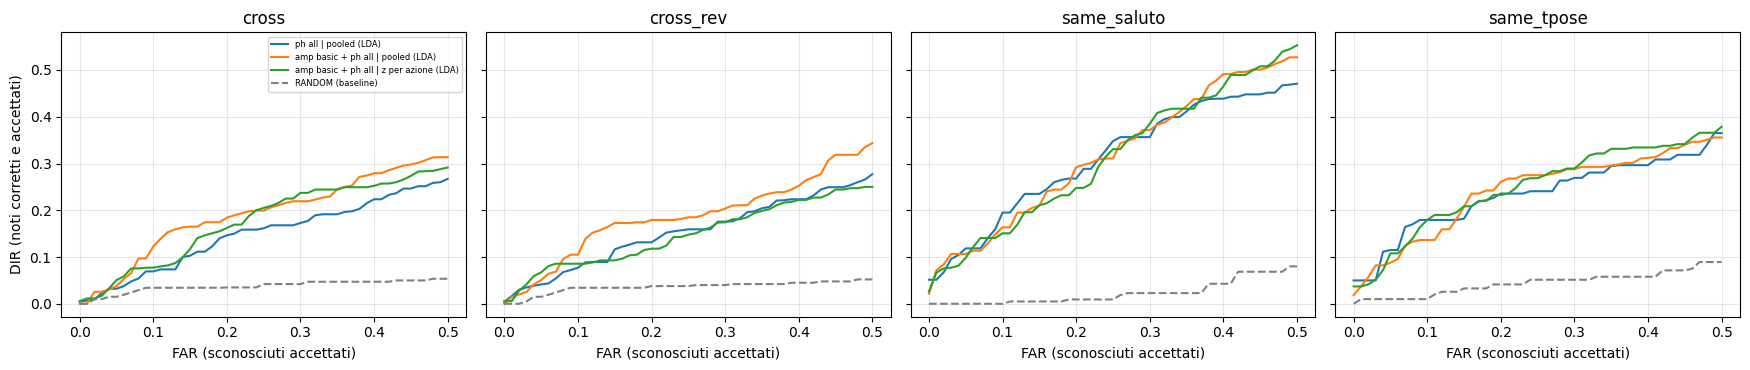

In [8]:
fars = np.linspace(0.0, 0.5, 51)
show = [MODEL_NAMES[i] for i in (1, 3, 4, 5)]
fig, ax = plt.subplots(1, len(PROTOCOLS), figsize=(4.4 * len(PROTOCOLS), 3.8), sharey=True)
for a, proto in zip(ax, PROTOCOLS):
    for name in show:
        mi = MODEL_NAMES.index(name)
        pooled = pool([arrays[(mi, proto, f)] for f in range(len(folds))])
        a.plot(fars, [dir_at_far(pooled, 'max', fr)[0]['DIR'] for fr in fars], label=name if proto == PROTOCOLS[0] else None,
               ls='--' if 'RANDOM' in name else '-', color='gray' if 'RANDOM' in name else None)
    a.set_title(proto); a.set_xlabel('FAR (sconosciuti accettati)'); a.grid(alpha=0.3)
ax[0].set_ylabel('DIR (noti corretti e accettati)'); ax[0].legend(fontsize=6)
plt.tight_layout(); plt.show()

## 8. Come leggere i risultati

* **DIR@FAR 5% contro Rank-1 noti**: il Rank-1 è il tetto (identificazione senza rifiuto); il DIR mostra quanto se ne perde quando si impone di rifiutare gli sconosciuti. Il gap è il costo del rifiuto.
* **Scomposizione**: *accettati ma sbagliati* sono errori di identità che nessuna soglia può correggere; *rifiutati* sono noti scartati per punteggio basso. Una soglia più alta riduce i falsi accettati ma aumenta i rifiutati.
* **`margin` contro `max`**: se `margin` ha AUROC/DIR migliori, conviene usarlo come punteggio di accettazione.
* **Soglia calibrata (§6)**: se il FAR reale è molto diverso dall'obiettivo, la soglia non si trasferisce fra identità: in un sistema reale servirebbe ricalibrarla.
* **Confronto con la baseline casuale**: dà il livello da superare; con embedding casuali il DIR ≈ FAR × (1/n_known).
* **Cross contro stessa azione**: nei risultati precedenti il cambio d'azione costava circa 10–11 punti di mAP; qui si vede lo stesso effetto sul rifiuto degli sconosciuti.
* Con 4 fold e 4 identità sconosciute per fold, le deviazioni standard sono ampie: differenze di pochi punti non sono significative. Ripeti con altri `seed` o con `n_folds=11` per più stabilità.